# Student At-Risk Identification: Gradient Boosting (refactored)

IT3091 Machine Learning | Group 2026-AI-53

**Objective:** Implement and evaluate Gradient Boosting models on the UCI Student Performance datasets (Mathematics and Portuguese) to identify students at risk of poor academic performance, and assess how well each model detects at-risk students.

**Methodology (unchanged from the original notebook):**
- Target: **At-Risk = 1 when `G3 < 10`**, otherwise Not-At-Risk = 0.
- Inputs: every column except `G1`, `G2`, `G3`, so the model does not use grades to predict grades.
- Mathematics and Portuguese are modelled **separately**.
- Stratified 80/20 train-test split, `random_state=42`.
- Baseline: default `GradientBoostingClassifier`. Tuning: `GridSearchCV`, 5-fold stratified CV, scored by F1 on the training data only.

**Workflow:** Step 1 Setup and loading, Step 2 EDA, Step 3 Target and features, Step 4 Split and preprocessing, Step 5 Baseline, Step 6 Tuning, Step 7 Tuned evaluation, Step 8 Baseline versus tuned, Step 9 Feature importance, Step 10 Final results.

Every conclusion printed in Steps 5 to 10 is computed from the model outputs of the current run, so the text updates when the notebook is re-run.

## Step 1: Project setup and data loading

- **What are we doing?** Importing every library once, defining all settings and paths in one cell, and loading both CSV files once.
- **Why?** A single configuration cell prevents the seed, paths or column lists from drifting between cells. Loading once means every later step uses identical data.
- **What does the code produce?** The shape and column check for each dataset.
- **How to interpret it?** Both datasets should have 33 columns and identical column names. The Portuguese file has more rows than the Mathematics file.
- **What happens next?** Step 2 inspects the data quality and distributions.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- Experiment settings (the only place these are defined) ----
RANDOM_STATE = 42          # same seed for the split, CV folds and models
TEST_SIZE = 0.20
CV_SPLITS = 5
TARGET_COLUMN = "G3"
RISK_THRESHOLD = 10        # G3 below this value means At-Risk
EXCLUDED_FEATURES = ["G1", "G2", "G3"]   # grades are never used as predictors
SUBJECTS = ["Mathematics", "Portuguese"]
FILE_NAMES = {"Mathematics": "student-mat.csv", "Portuguese": "student-por.csv"}
CLASS_NAMES = ["Not-At-Risk", "At-Risk"]
METRICS = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
SAVE_OUTPUTS = True        # set False to skip writing models and CSV reports

# ---- Paths (the only place these are defined) ----
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif not (ROOT / "data" / "raw").exists() and (ROOT / "student-risk-intelligence" / "data" / "raw").exists():
    ROOT = ROOT / "student-risk-intelligence"

DATA_DIR = ROOT / "data" / "raw"
MODEL_DIR = ROOT / "notebooks" / "models"
REPORT_DIR = ROOT / "notebooks" / "reports"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

print("Project root:", ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())

Project root: C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project
Data directory: C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\data\raw


In [2]:
# Load each CSV once. The UCI files are semicolon separated.
missing_files = [DATA_DIR / FILE_NAMES[s] for s in SUBJECTS if not (DATA_DIR / FILE_NAMES[s]).exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing dataset file(s):\n" + "\n".join(str(p) for p in missing_files)
        + "\nOpen the notebook from the project folder or update ROOT above."
    )

raw = {s: pd.read_csv(DATA_DIR / FILE_NAMES[s], sep=";") for s in SUBJECTS}

for s, df in raw.items():
    print(f"{s}: {df.shape[0]} rows x {df.shape[1]} columns")

print("\nColumns identical in both files:",
      raw["Mathematics"].columns.tolist() == raw["Portuguese"].columns.tolist())
print("\nColumns:", raw["Mathematics"].columns.tolist())

FileNotFoundError: Missing dataset file(s):
c:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\data\raw\student-mat.csv
c:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\data\raw\student-por.csv
Open the notebook from the project folder or update ROOT above.

## Step 2: Data understanding and exploratory data analysis

- **What are we doing?** Looking at sample records, data types, summary statistics, data quality, class balance and the relationship between inputs and risk.
- **Why?** EDA shows whether the classes are imbalanced (which makes accuracy misleading) and which inputs vary with risk. These charts describe the data. They do not prove that any feature causes risk.
- **What does the code produce?** Quality table, sample rows, class balance and `G3` histogram, input distributions, correlation with the risk label, and at-risk rate for four categorical features.
- **How to interpret it?** The printed "Observation" lines under each chart are computed from the data.
- **What happens next?** Step 3 formally defines the target and the predictor columns.

In [ ]:
# Data quality summary and a first look at the records
quality = pd.DataFrame({
    s: {
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Numeric columns": df.select_dtypes(include="number").shape[1],
        "Categorical columns": df.select_dtypes(exclude="number").shape[1],
        "Missing values": int(df.isnull().sum().sum()),
        "Duplicate rows": int(df.duplicated().sum()),
        "Distinct G3 values": df["G3"].nunique(),
    }
    for s, df in raw.items()
})
display(quality)

for s, df in raw.items():
    print(f"\n{s}: first 3 records")
    display(df.head(3))
    print(f"{s}: descriptive statistics (numeric columns)")
    display(df.describe().T.round(2))

,Mathematics,Portuguese
Rows,395,649
Columns,33,33
Numeric columns,16,16
Categorical columns,17,17
Missing values,0,0
Duplicate rows,0,0
Distinct G3 values,18,17



Mathematics: first 3 records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10


Mathematics: descriptive statistics (numeric columns)


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0



Portuguese: first 3 records


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12


Portuguese: descriptive statistics (numeric columns)


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


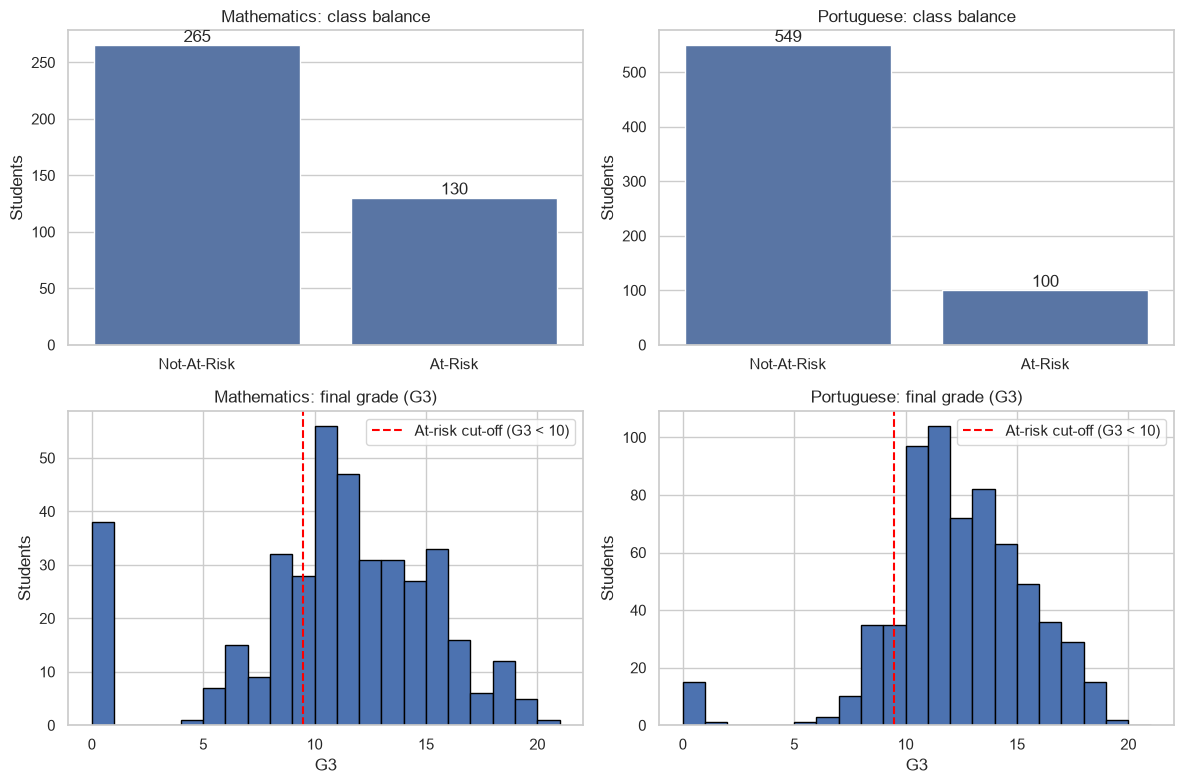

Observation: Mathematics: 32.9% of students are At-Risk, so the At-Risk class is the minority.
Observation: Portuguese: 15.4% of students are At-Risk, so the At-Risk class is the minority.
Because the classes are unequal, Precision, Recall and F1 for the At-Risk class matter more than Accuracy.


In [ ]:
# Class balance and the G3 distribution relative to the at-risk cut-off
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, s in enumerate(SUBJECTS):
    df = raw[s]
    labels = (df[TARGET_COLUMN] < RISK_THRESHOLD).map({True: "At-Risk", False: "Not-At-Risk"})
    sns.countplot(x=labels, order=CLASS_NAMES, ax=axes[0, col])
    axes[0, col].set_title(f"{s}: class balance")
    axes[0, col].set_xlabel("")
    axes[0, col].set_ylabel("Students")
    for container in axes[0, col].containers:
        axes[0, col].bar_label(container)

    axes[1, col].hist(df[TARGET_COLUMN], bins=range(0, 22), edgecolor="black")
    axes[1, col].axvline(RISK_THRESHOLD - 0.5, color="red", linestyle="--", label=f"At-risk cut-off (G3 < {RISK_THRESHOLD})")
    axes[1, col].set_title(f"{s}: final grade (G3)")
    axes[1, col].set_xlabel("G3")
    axes[1, col].set_ylabel("Students")
    axes[1, col].legend()
plt.tight_layout()
plt.show()

for s in SUBJECTS:
    share = (raw[s][TARGET_COLUMN] < RISK_THRESHOLD).mean() * 100
    print(f"Observation: {s}: {share:.1f}% of students are At-Risk, so the At-Risk class is the minority."
          if share < 50 else f"Observation: {s}: {share:.1f}% of students are At-Risk.")
print("Because the classes are unequal, Precision, Recall and F1 for the At-Risk class matter more than Accuracy.")

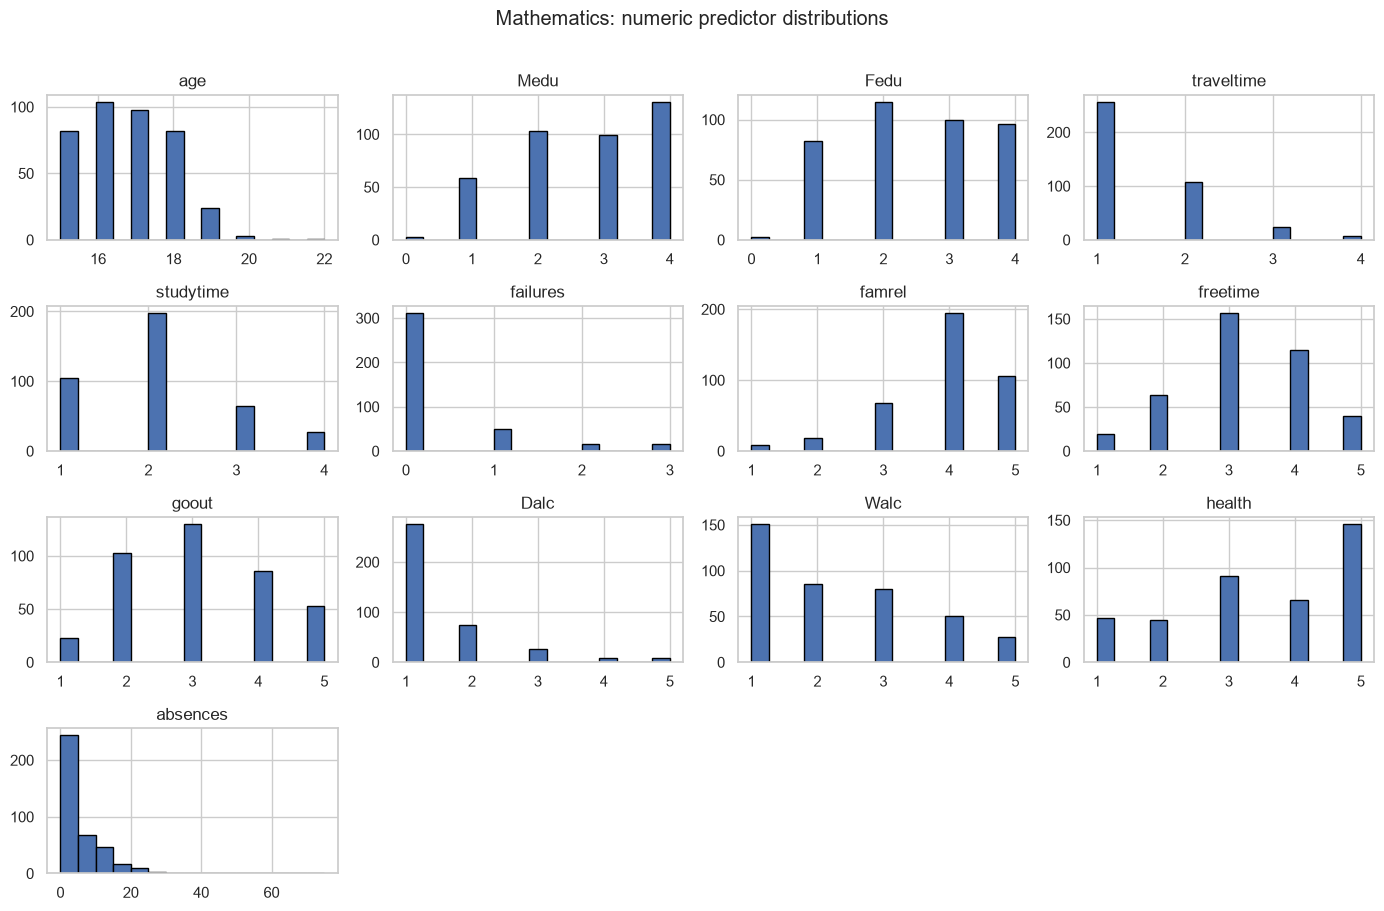

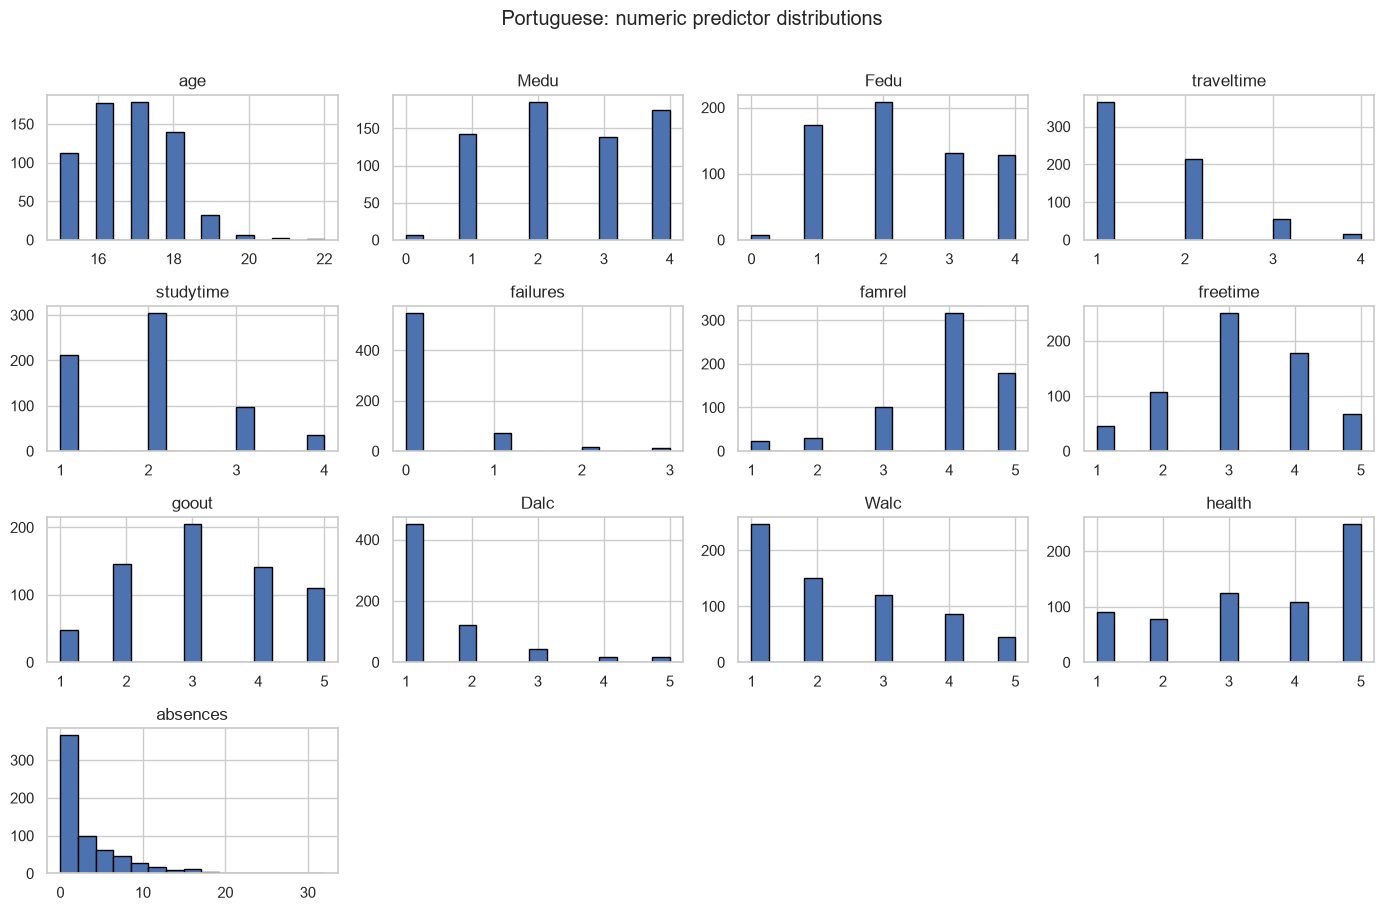

Observation guide: look for skew (for example absences) and for ordinal scales that take only a few values.


In [ ]:
# Distributions of the numeric predictors (grades excluded because they are not model inputs)
for s in SUBJECTS:
    numeric_predictors = [c for c in raw[s].select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    raw[s][numeric_predictors].hist(figsize=(14, 9), bins=15, edgecolor="black", layout=(4, 4))
    plt.suptitle(f"{s}: numeric predictor distributions", y=1.01)
    plt.tight_layout()
    plt.show()
print("Observation guide: look for skew (for example absences) and for ordinal scales that take only a few values.")

Observation: Mathematics: strongest linear associations with risk: failures (+0.34), goout (+0.18), age (+0.18)
Observation: Portuguese: strongest linear associations with risk: failures (+0.38), studytime (-0.17), Fedu (-0.15)


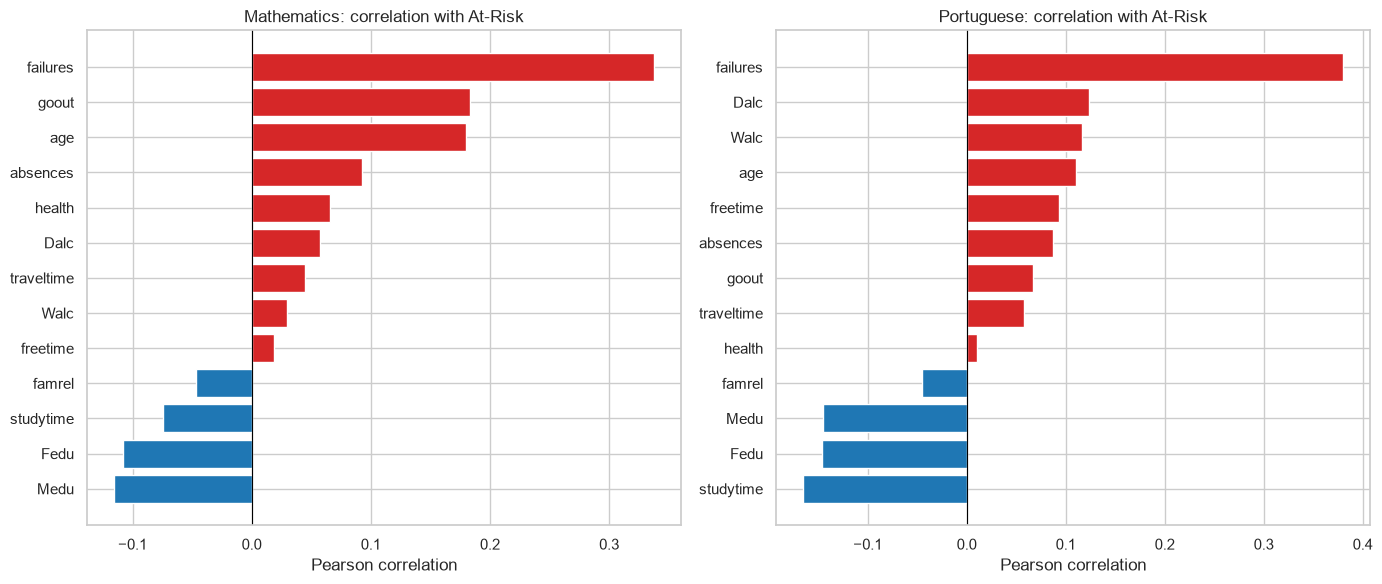

In [ ]:
# Correlation of each numeric predictor with the At-Risk label (association, not causation)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, s in zip(axes, SUBJECTS):
    df = raw[s]
    risk = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    numeric_predictors = [c for c in df.select_dtypes(include="number").columns if c not in EXCLUDED_FEATURES]
    corr = df[numeric_predictors].corrwith(risk).sort_values()
    ax.barh(corr.index, corr.values, color=["tab:red" if v > 0 else "tab:blue" for v in corr.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{s}: correlation with At-Risk")
    ax.set_xlabel("Pearson correlation")
    top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(3)
    print(f"Observation: {s}: strongest linear associations with risk: "
          + ", ".join(f"{k} ({v:+.2f})" for k, v in top.items()))
plt.tight_layout()
plt.show()

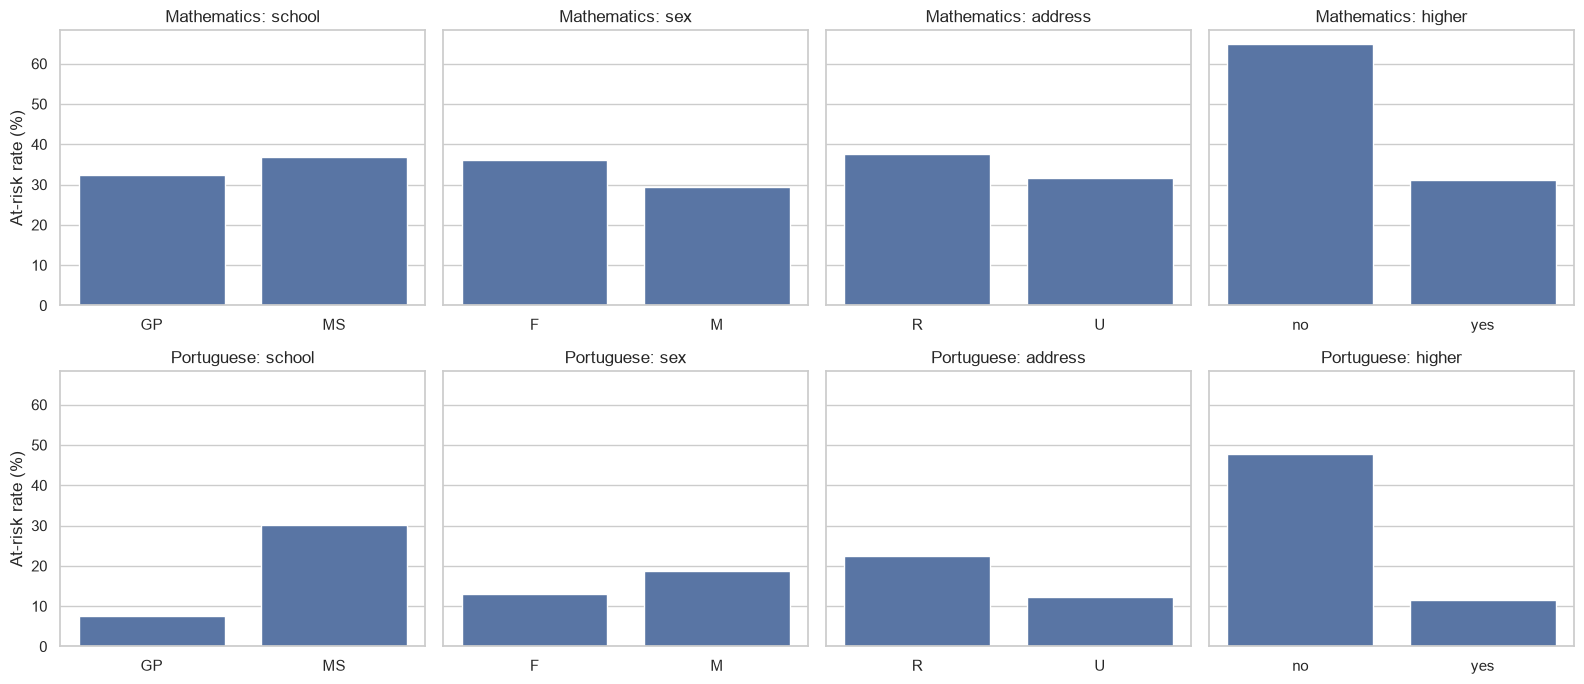

Observation guide: a large gap between categories means the groups differ in risk. It does not show why.


In [ ]:
# At-risk rate by category for four informative categorical features
cat_cols = ["school", "sex", "address", "higher"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for row, s in enumerate(SUBJECTS):
    df = raw[s].copy()
    df["at_risk"] = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    for col, name in enumerate(cat_cols):
        rate = df.groupby(name)["at_risk"].mean().mul(100)
        sns.barplot(x=rate.index, y=rate.values, ax=axes[row, col])
        axes[row, col].set_title(f"{s}: {name}")
        axes[row, col].set_xlabel("")
        axes[row, col].set_ylabel("At-risk rate (%)")
plt.tight_layout()
plt.show()
print("Observation guide: a large gap between categories means the groups differ in risk. It does not show why.")

## Step 3: Target definition and feature preparation

- **What are we doing?** Creating the binary target and removing `G1`, `G2` and `G3` from the predictors.
- **Why?** `G3` defines the label, and `G1` and `G2` are earlier grades in the same course. Using them would let the model infer risk from grades, which defeats early identification. All other columns are kept as predictors.
- **What does the code produce?** One `prepare_features` function, the feature and target shapes, leakage checks, and the numeric and categorical column lists.
- **How to interpret it?** Both checks must print `True`. The feature count should be the original column count minus three.
- **What happens next?** Step 4 splits the data and builds the preprocessing pipeline.

In [ ]:
def prepare_features(df):
    """Return predictors X and the At-Risk target y (1 = G3 below the cut-off)."""
    y = (df[TARGET_COLUMN] < RISK_THRESHOLD).astype(int)
    X = df.drop(columns=EXCLUDED_FEATURES).copy()   # leakage control: no grade columns
    return X, y

features, target = {}, {}
for s in SUBJECTS:
    features[s], target[s] = prepare_features(raw[s])

feature_summary = pd.DataFrame({
    s: {
        "Predictor columns": features[s].shape[1],
        "Numeric predictors": features[s].select_dtypes(include="number").shape[1],
        "Categorical predictors": features[s].select_dtypes(exclude="number").shape[1],
        "At-Risk students": int(target[s].sum()),
        "Not-At-Risk students": int((1 - target[s]).sum()),
        "Grade columns excluded from inputs": all(c not in features[s].columns for c in EXCLUDED_FEATURES),
        "Target values": str([int(v) for v in sorted(target[s].unique())]),
    }
    for s in SUBJECTS
})
display(feature_summary)

print("Numeric predictors:", features["Mathematics"].select_dtypes(include="number").columns.tolist())
print("\nCategorical predictors:", features["Mathematics"].select_dtypes(exclude="number").columns.tolist())

,Mathematics,Portuguese
Predictor columns,30,30
Numeric predictors,13,13
Categorical predictors,17,17
At-Risk students,130,100
Not-At-Risk students,265,549
Grade columns excluded from inputs,True,True
Target values,"[0, 1]","[0, 1]"


Numeric predictors: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical predictors: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


## Step 4: Train-test split and preprocessing

- **What are we doing?** Splitting each subject into 80% training and 20% test data (stratified), and defining one preprocessing-plus-model pipeline.
- **Why?** Stratification keeps the At-Risk share similar in both parts. Putting imputation, scaling and one-hot encoding inside the `Pipeline` means they are learned from training data only, and inside each CV fold during tuning, so the test set never influences them.
- **What does the code produce?** A `data` dictionary holding each subject's split, a split summary, and the `build_gb_pipeline` function.
- **How to interpret it?** The training and test At-Risk percentages should be almost equal.
- **What happens next?** Step 5 fits the baseline on the training data and scores it once on the test data.

Note: numeric scaling is kept from the original notebook. Tree-based Gradient Boosting does not need it, and it does not change the results materially.

In [ ]:
# Stratified split, identical for the baseline and the tuned model
data = {}
for s in SUBJECTS:
    X_train, X_test, y_train, y_test = train_test_split(
        features[s], target[s],
        test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=target[s],
    )
    data[s] = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test}

split_summary = pd.DataFrame({
    s: {
        "Training records": len(d["X_train"]),
        "Test records": len(d["X_test"]),
        "Training At-Risk (%)": round(d["y_train"].mean() * 100, 2),
        "Test At-Risk (%)": round(d["y_test"].mean() * 100, 2),
        "Test At-Risk students": int(d["y_test"].sum()),
    }
    for s, d in data.items()
})
display(split_summary)

,Mathematics,Portuguese
Training records,316.00,519.00
Test records,79.00,130.00
Training At-Risk (%),32.91,15.41
Test At-Risk (%),32.91,15.38
Test At-Risk students,26.00,20.00


In [ ]:
def build_gb_pipeline(X_train):
    """Preprocessing + Gradient Boosting. Unfitted: every fit learns from the data it is given."""
    numeric = X_train.select_dtypes(include="number").columns.tolist()
    categorical = X_train.select_dtypes(exclude="number").columns.tolist()

    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocessor = ColumnTransformer([
        ("num", numeric_steps, numeric),
        ("cat", categorical_steps, categorical),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ])


def evaluate_model(model, X_test, y_test):
    """Score a fitted model on the held-out test set with the same definitions every time."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    return {"metrics": metrics, "y_pred": y_pred, "y_prob": y_prob}


def plot_confusion_matrices(evaluations, title, cmap):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, s in zip(axes, SUBJECTS):
        cm = confusion_matrix(data[s]["y_test"], evaluations[s]["y_pred"], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax.set_title(f"{s}: {title}")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")
    plt.tight_layout()
    plt.show()


def plot_roc_and_pr(evaluations, title):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for i, s in enumerate(SUBJECTS):
        y_test, prob = data[s]["y_test"], evaluations[s]["y_prob"]
        RocCurveDisplay.from_predictions(y_test, prob, name=s, ax=axes[i])
        axes[i].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
        axes[i].set_title(f"{s}: {title} ROC curve")
        PrecisionRecallDisplay.from_predictions(y_test, prob, name=s, ax=axes[2 + i])
        axes[2 + i].set_title(f"{s}: {title} precision-recall curve")
    plt.tight_layout()
    plt.show()


def describe_confusion(evaluations, label):
    """Plain-language reading of each confusion matrix, computed from the results."""
    for s in SUBJECTS:
        tn, fp, fn, tp = confusion_matrix(data[s]["y_test"], evaluations[s]["y_pred"], labels=[0, 1]).ravel()
        print(f"{label} {s}: detected {tp} of {tp + fn} at-risk students (recall {tp / (tp + fn):.0%}); "
              f"missed {fn}; flagged {fp} not-at-risk students unnecessarily.")

print("Pipeline and evaluation helpers defined.")

Pipeline and evaluation helpers defined.


## Step 5: Baseline Gradient Boosting model (before tuning)

- **What are we doing?** Training Gradient Boosting with its default settings (`GradientBoostingClassifier(random_state=42)`) as the reference point.
- **Why?** Without a baseline we cannot tell whether tuning helps. Gradient Boosting builds shallow trees one after another, and each new tree tries to correct the errors of the ensemble so far. The default settings are `n_estimators=100`, `learning_rate=0.1`, `max_depth=3` and `min_samples_leaf=1`.
- **What does the code produce?** A fitted baseline model per subject, a metrics table, confusion matrices, ROC and precision-recall curves.
- **How to interpret it?** Accuracy is the share of correct predictions. Precision is the share of flagged students who are truly at risk. Recall is the share of truly at-risk students that were found. F1 balances the two. ROC-AUC measures how well risk scores rank students regardless of threshold. A **false negative** is an at-risk student who was missed, which is the costly error for early support. A **false positive** is an extra follow-up.
- **What happens next?** Step 6 searches for better hyperparameters using training data only.

In [ ]:
# Fit on training data only, score once on the held-out test set
baseline_models, baseline_eval = {}, {}
for s in SUBJECTS:
    model = build_gb_pipeline(data[s]["X_train"])
    model.fit(data[s]["X_train"], data[s]["y_train"])
    baseline_models[s] = model
    baseline_eval[s] = evaluate_model(model, data[s]["X_test"], data[s]["y_test"])

    print(f"\n{'=' * 50}\n{s}: baseline classification report (test set)\n{'=' * 50}")
    print(classification_report(data[s]["y_test"], baseline_eval[s]["y_pred"],
                                target_names=CLASS_NAMES, zero_division=0))

baseline_df = pd.DataFrame(
    [{"Dataset": s, **baseline_eval[s]["metrics"]} for s in SUBJECTS]
)
print("Baseline test metrics")
display(baseline_df.round(4))


Mathematics: baseline classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.70      0.85      0.77        53
     At-Risk       0.47      0.27      0.34        26

    accuracy                           0.66        79
   macro avg       0.58      0.56      0.56        79
weighted avg       0.63      0.66      0.63        79


Portuguese: baseline classification report (test set)
              precision    recall  f1-score   support

 Not-At-Risk       0.87      0.95      0.91       110
     At-Risk       0.44      0.20      0.28        20

    accuracy                           0.84       130
   macro avg       0.66      0.58      0.59       130
weighted avg       0.80      0.84      0.81       130

Baseline test metrics


,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Mathematics,0.6582,0.4667,0.2692,0.3415,0.6727
1,Portuguese,0.8385,0.4444,0.2000,0.2759,0.7905


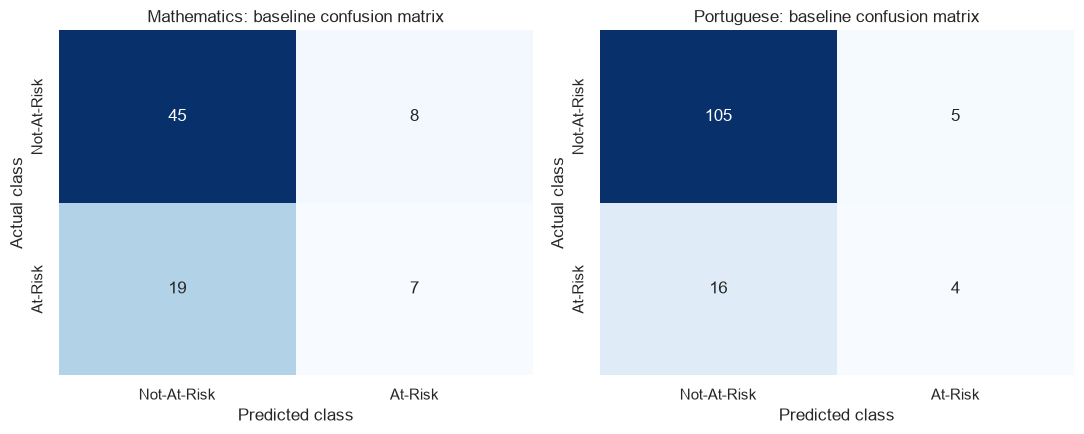

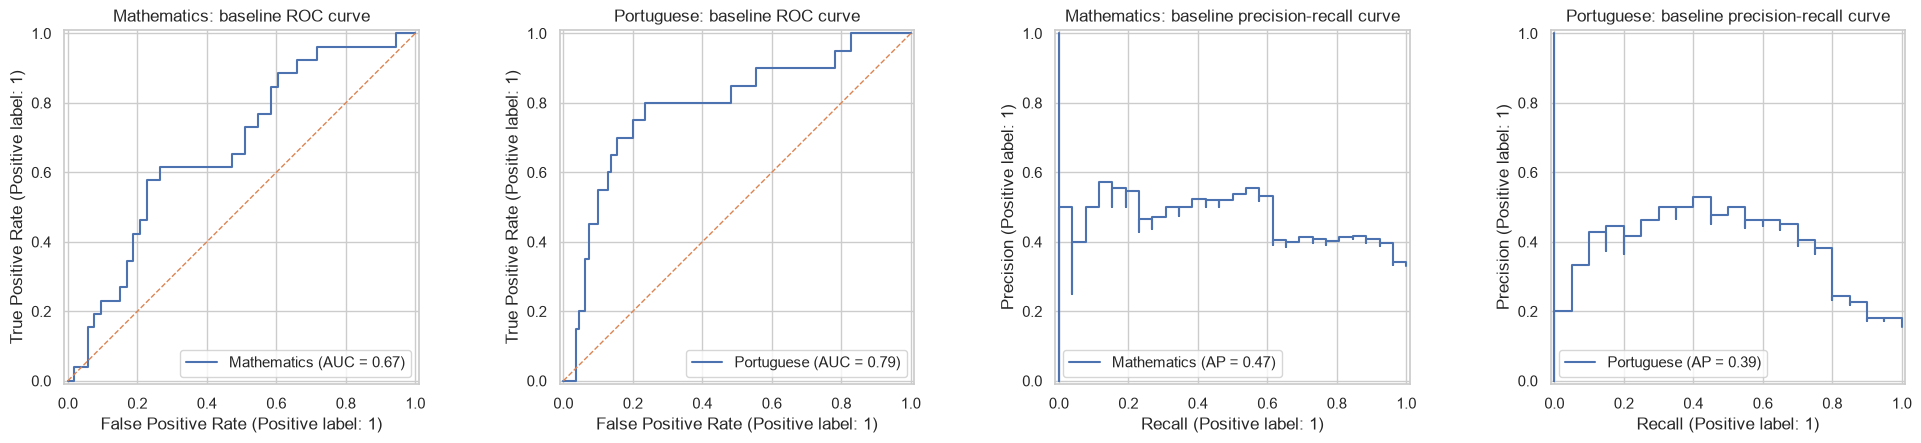

Baseline Mathematics: detected 7 of 26 at-risk students (recall 27%); missed 19; flagged 8 not-at-risk students unnecessarily.
Baseline Portuguese: detected 4 of 20 at-risk students (recall 20%); missed 16; flagged 5 not-at-risk students unnecessarily.


In [ ]:
plot_confusion_matrices(baseline_eval, "baseline confusion matrix", "Blues")
plot_roc_and_pr(baseline_eval, "baseline")
describe_confusion(baseline_eval, "Baseline")

## Step 6: Hyperparameter tuning

- **What are we doing?** Running `GridSearchCV` over 24 combinations of four hyperparameters, using 5-fold stratified cross-validation on the **training data only**. The score used to choose is **F1 for the At-Risk class**.
- **Why these parameters?**
  - `n_estimators` (50, 100): the number of boosting stages. More stages fit the training data more closely.
  - `learning_rate` (0.05, 0.1): how much each tree contributes. Smaller values learn more slowly and are usually more stable.
  - `max_depth` (1, 2, 3): the depth of each tree. Deeper trees capture interactions but overfit more easily.
  - `min_samples_leaf` (2, 5): the minimum students per leaf. Larger values smooth the model.
- **Why F1?** It rewards finding at-risk students without flagging too many others. The test set is not touched in this step.
- **What does the code produce?** The best parameters, the best mean CV F1, the top five configurations, and the CV F1 of the baseline settings for a fair training-only comparison.
- **How to interpret it?** CV F1 values come from the training folds. They are not test results. Small gaps between ranked configurations mean the choice is not strongly determined by the data.
- **What happens next?** Step 7 evaluates the selected model on the same test set used for the baseline.

In [ ]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_leaf": [2, 5],
}

grids, tuning_rows = {}, []
for s in SUBJECTS:
    X_train, y_train = data[s]["X_train"], data[s]["y_train"]

    grid = GridSearchCV(build_gb_pipeline(X_train), param_grid,
                        scoring="f1", cv=cv, n_jobs=1)
    grid.fit(X_train, y_train)          # training data only
    grids[s] = grid

    # Baseline settings scored with the same folds, so CV F1 values are comparable
    baseline_cv_f1 = cross_val_score(build_gb_pipeline(X_train), X_train, y_train,
                                     cv=cv, scoring="f1").mean()
    tuning_rows.append({
        "Dataset": s,
        "Best parameters": {k.replace("classifier__", ""): v for k, v in grid.best_params_.items()},
        "Best CV F1": grid.best_score_,
        "Baseline CV F1 (default settings)": baseline_cv_f1,
    })

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df.round(4))

for s in SUBJECTS:
    res = pd.DataFrame(grids[s].cv_results_).sort_values("rank_test_score").head(5)
    top5 = res[["rank_test_score", "mean_test_score", "std_test_score", "params"]].copy()
    top5["params"] = top5["params"].apply(lambda p: {k.replace("classifier__", ""): v for k, v in p.items()})
    print(f"\n{s}: top 5 configurations by mean CV F1")
    display(top5.rename(columns={"rank_test_score": "Rank", "mean_test_score": "Mean CV F1",
                                 "std_test_score": "Std CV F1", "params": "Parameters"}).round(4))

,Dataset,Best parameters,Best CV F1,Baseline CV F1 (default settings)
0,Mathematics,"{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}",0.4472,0.4521
1,Portuguese,"{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 50}",0.4201,0.3757



Mathematics: top 5 configurations by mean CV F1


,Rank,Mean CV F1,Std CV F1,Parameters
9,1,0.4472,0.0582,"{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}"
21,2,0.4364,0.0872,"{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}"
16,3,0.4333,0.0765,"{'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'n_estimators': 50}"
11,4,0.4255,0.0635,"{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 100}"
17,5,0.4243,0.0736,"{'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'n_estimators': 100}"



Portuguese: top 5 configurations by mean CV F1


,Rank,Mean CV F1,Std CV F1,Parameters
20,1,0.4201,0.1116,"{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 50}"
22,2,0.4168,0.1462,"{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 50}"
9,3,0.4049,0.1634,"{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}"
21,4,0.3974,0.1505,"{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}"
11,5,0.3949,0.1230,"{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 100}"


In [ ]:
for s in SUBJECTS:
    best = tuning_df.loc[tuning_df["Dataset"] == s].iloc[0]
    gain = best["Best CV F1"] - best["Baseline CV F1 (default settings)"]
    direction = "higher" if gain > 0 else "lower" if gain < 0 else "equal"
    print(f"Observation: {s}: best CV F1 {best['Best CV F1']:.4f} is {direction} than the default settings' "
          f"CV F1 {best['Baseline CV F1 (default settings)']:.4f} (difference {gain:+.4f}).")
    if gain < 0:
        print("  The grid does not contain the default settings (the default min_samples_leaf is 1, the grid starts at 2), "
              "so the best grid configuration can score below the default.")

Observation: Mathematics: best CV F1 0.4472 is lower than the default settings' CV F1 0.4521 (difference -0.0049).
  The grid does not contain the default settings (the default min_samples_leaf is 1, the grid starts at 2), so the best grid configuration can score below the default.
Observation: Portuguese: best CV F1 0.4201 is higher than the default settings' CV F1 0.3757 (difference +0.0445).


## Step 7: Tuned model evaluation

- **What are we doing?** Taking the best pipeline from each grid search (already refitted on the full training set) and scoring it on the held-out test set.
- **Why?** The test set was used for nothing so far except the baseline score, so it is a fair, identical yardstick for both models. Metrics use exactly the same function as in Step 5.
- **What does the code produce?** Tuned test metrics, confusion matrices, ROC and precision-recall curves.
- **How to interpret it?** Compare against Step 5 only in Step 8. Do not compare these test scores with the CV F1 values from Step 6, because they come from different data.
- **What happens next?** Step 8 places baseline and tuned results side by side.

In [ ]:
tuned_models = {s: grids[s].best_estimator_ for s in SUBJECTS}
tuned_eval = {s: evaluate_model(tuned_models[s], data[s]["X_test"], data[s]["y_test"]) for s in SUBJECTS}

tuned_df = pd.DataFrame(
    [{"Dataset": s, **tuned_eval[s]["metrics"]} for s in SUBJECTS]
)
print("Tuned test metrics")
display(tuned_df.round(4))

Tuned test metrics


,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Mathematics,0.6709,0.5,0.2692,0.3500,0.6372
1,Portuguese,0.8308,0.4,0.2000,0.2667,0.7800


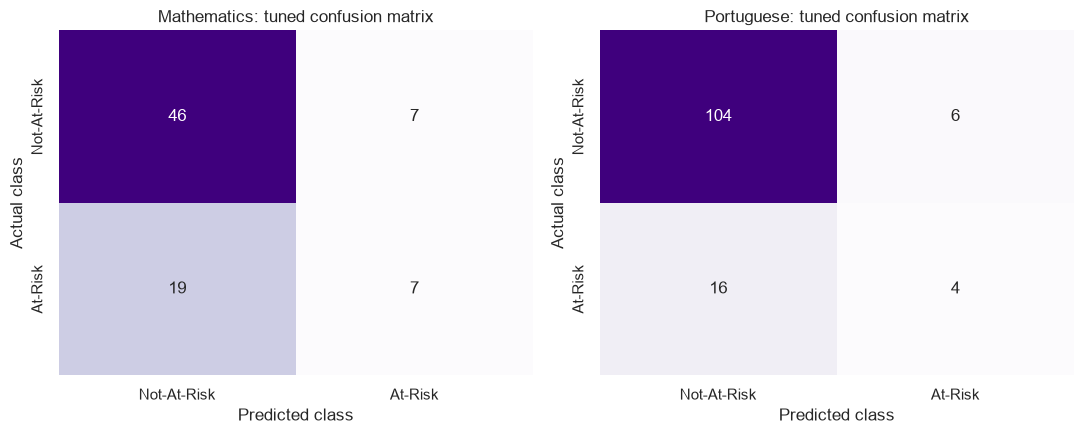

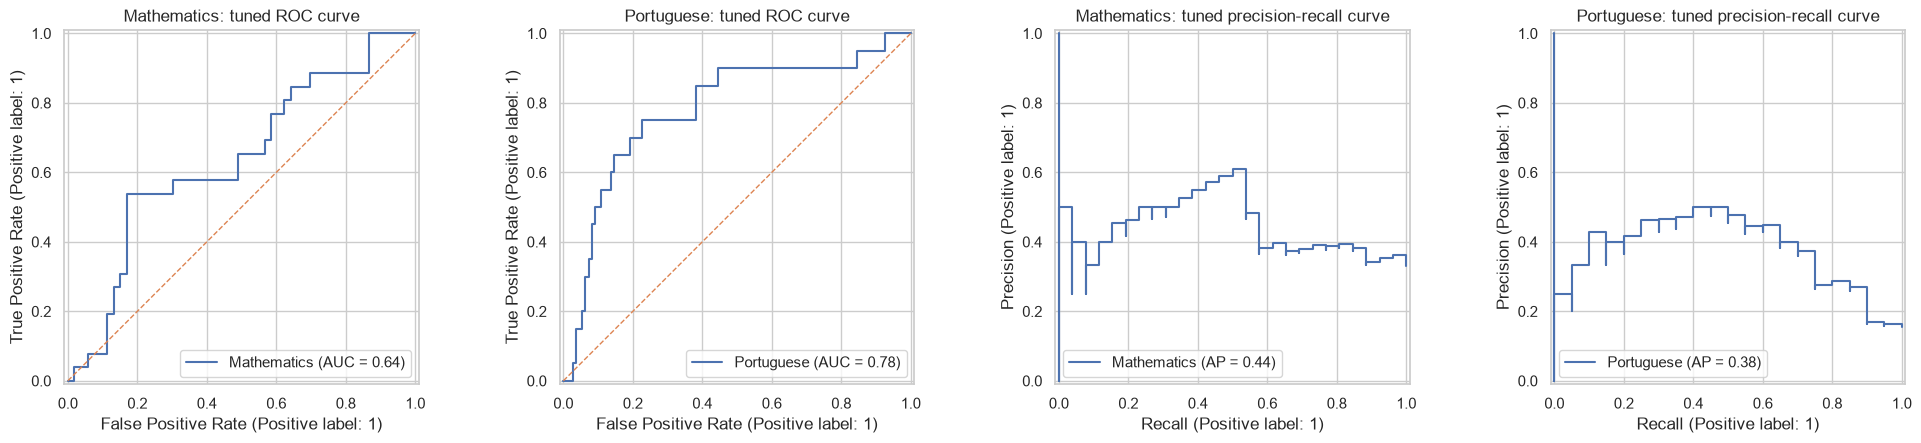

Tuned Mathematics: detected 7 of 26 at-risk students (recall 27%); missed 19; flagged 7 not-at-risk students unnecessarily.
Tuned Portuguese: detected 4 of 20 at-risk students (recall 20%); missed 16; flagged 6 not-at-risk students unnecessarily.


In [ ]:
plot_confusion_matrices(tuned_eval, "tuned confusion matrix", "Purples")
plot_roc_and_pr(tuned_eval, "tuned")
describe_confusion(tuned_eval, "Tuned")

## Step 8: Baseline versus tuned comparison

- **What are we doing?** Putting baseline and tuned test metrics side by side for each dataset.
- **Why?** Tuning is not guaranteed to help on unseen data. The comparison shows which metrics improved, which declined, and whether there is a trade-off such as higher recall at the cost of precision.
- **What does the code produce?** One table per dataset with the change in every metric, a grouped bar chart, and a computed summary of improvements and declines.
- **How to interpret it?** The test set is small, so one student changes recall by a visible amount. The summary prints how many at-risk students the test set contains so you can judge this.
- **What happens next?** Step 9 examines which features the fitted models relied on.


Mathematics: baseline versus tuned (held-out test set)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.6582,0.6709,0.0127
Precision,0.4667,0.5000,0.0333
Recall,0.2692,0.2692,0.0000
F1-Score,0.3415,0.3500,0.0085
ROC-AUC,0.6727,0.6372,-0.0356



Portuguese: baseline versus tuned (held-out test set)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.8385,0.8308,-0.0077
Precision,0.4444,0.4000,-0.0444
Recall,0.2000,0.2000,0.0000
F1-Score,0.2759,0.2667,-0.0092
ROC-AUC,0.7905,0.7800,-0.0105


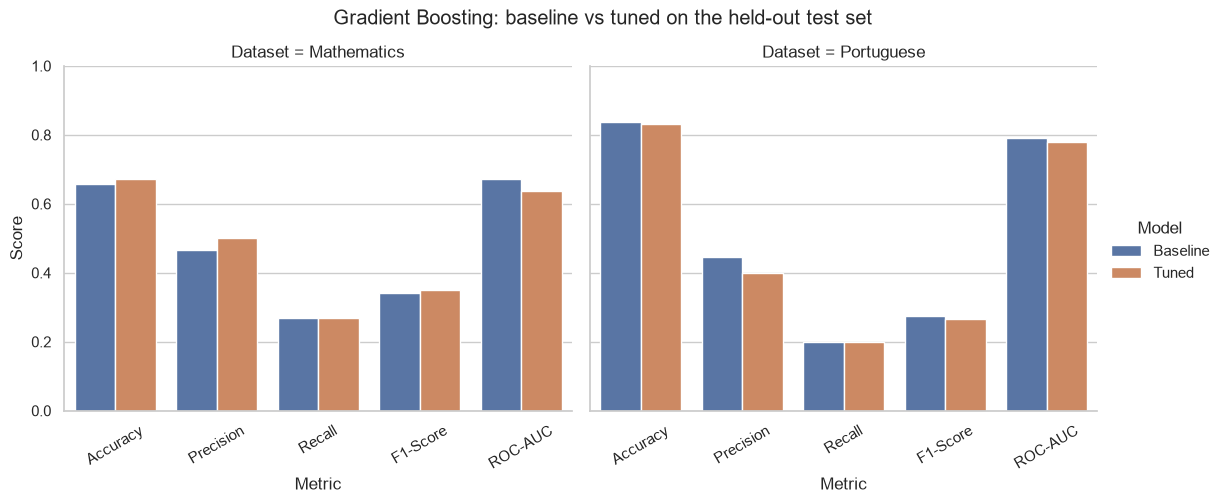

In [ ]:
comparison_long = pd.concat([
    baseline_df.assign(Model="Baseline"),
    tuned_df.assign(Model="Tuned"),
], ignore_index=True)

comparison_tables = {}
for s in SUBJECTS:
    b = baseline_df.set_index("Dataset").loc[s, METRICS]
    t = tuned_df.set_index("Dataset").loc[s, METRICS]
    table = pd.DataFrame({"Baseline": b, "Tuned": t, "Change (Tuned - Baseline)": t - b})
    comparison_tables[s] = table
    print(f"\n{s}: baseline versus tuned (held-out test set)")
    display(table.round(4))

plot_df = comparison_long.melt(id_vars=["Dataset", "Model"], value_vars=METRICS,
                               var_name="Metric", value_name="Score")
g = sns.catplot(data=plot_df, kind="bar", x="Metric", y="Score", hue="Model",
                col="Dataset", height=4.5, aspect=1.25)
g.set(ylim=(0, 1))
g.set_xticklabels(rotation=30)
g.figure.suptitle("Gradient Boosting: baseline vs tuned on the held-out test set", y=1.04)
plt.show()

In [ ]:
TOL = 1e-9
for s in SUBJECTS:
    change = comparison_tables[s]["Change (Tuned - Baseline)"]
    improved = [m for m in METRICS if change[m] > TOL]
    declined = [m for m in METRICS if change[m] < -TOL]
    unchanged = [m for m in METRICS if abs(change[m]) <= TOL]
    n_pos = int(data[s]["y_test"].sum())

    print(f"\n{s}")
    print(f"  Improved: {', '.join(improved) if improved else 'none'}")
    print(f"  Declined: {', '.join(declined) if declined else 'none'}")
    print(f"  Unchanged: {', '.join(unchanged) if unchanged else 'none'}")
    if improved and declined:
        print("  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on "
              "whether missing at-risk students or over-flagging is the bigger concern.")
    elif not improved and declined:
        print("  Tuning did not improve any test metric for this dataset.")
    elif improved and not declined:
        print("  Tuning improved test metrics without a decline in any metric.")
    cv_gain = tuning_df.set_index("Dataset").loc[s, "Best CV F1"] - tuning_df.set_index("Dataset").loc[s, "Baseline CV F1 (default settings)"]
    f1_change = change["F1-Score"]
    if (cv_gain > 0) != (f1_change > 0):
        print(f"  Note: CV F1 changed by {cv_gain:+.4f} (tuned minus default settings) but test F1 changed by "
              f"{f1_change:+.4f}. The two point in different directions, which is common with small datasets.")
    print(f"  Caution: the test set contains {n_pos} at-risk students, so each missed student shifts recall by {1 / n_pos:.1%}.")


Mathematics
  Improved: Accuracy, Precision, F1-Score
  Declined: ROC-AUC
  Unchanged: Recall
  Trade-off: tuning improved some metrics and worsened others, so the preferred model depends on whether missing at-risk students or over-flagging is the bigger concern.
  Note: CV F1 changed by -0.0049 (tuned minus default settings) but test F1 changed by +0.0085. The two point in different directions, which is common with small datasets.
  Caution: the test set contains 26 at-risk students, so each missed student shifts recall by 3.8%.

Portuguese
  Improved: none
  Declined: Accuracy, Precision, F1-Score, ROC-AUC
  Unchanged: Recall
  Tuning did not improve any test metric for this dataset.
  Note: CV F1 changed by +0.0445 (tuned minus default settings) but test F1 changed by -0.0092. The two point in different directions, which is common with small datasets.
  Caution: the test set contains 20 at-risk students, so each missed student shifts recall by 5.0%.


## Step 9: Feature importance

- **What are we doing?** Reading `feature_importances_` from the tuned Gradient Boosting models and mapping each value back to the correct column of the fitted pipeline.
- **Why?** It shows which inputs the model relied on most. One-hot encoding splits a categorical column into several columns, so we also add them back up per original feature to make the ranking easier to read.
- **What does the code produce?** A top-5 table of transformed features and a top-10 chart of original features for each subject.
- **How to interpret it?** Importance describes how the fitted model used a feature. It **does not show that the feature causes risk**, and it can change if the data or seed changes. Correlated features share importance between them.
- **What happens next?** Step 10 collects everything into the final report.


Mathematics: top 5 transformed features


,Feature,Importance
5,num__failures,0.2134
12,num__absences,0.1759
23,cat__Mjob_at_home,0.0596
6,num__famrel,0.0440
8,num__goout,0.0342



Portuguese: top 5 transformed features


,Feature,Importance
5,num__failures,0.3159
34,cat__reason_home,0.0623
14,cat__school_MS,0.0549
12,num__absences,0.0541
13,cat__school_GP,0.0440


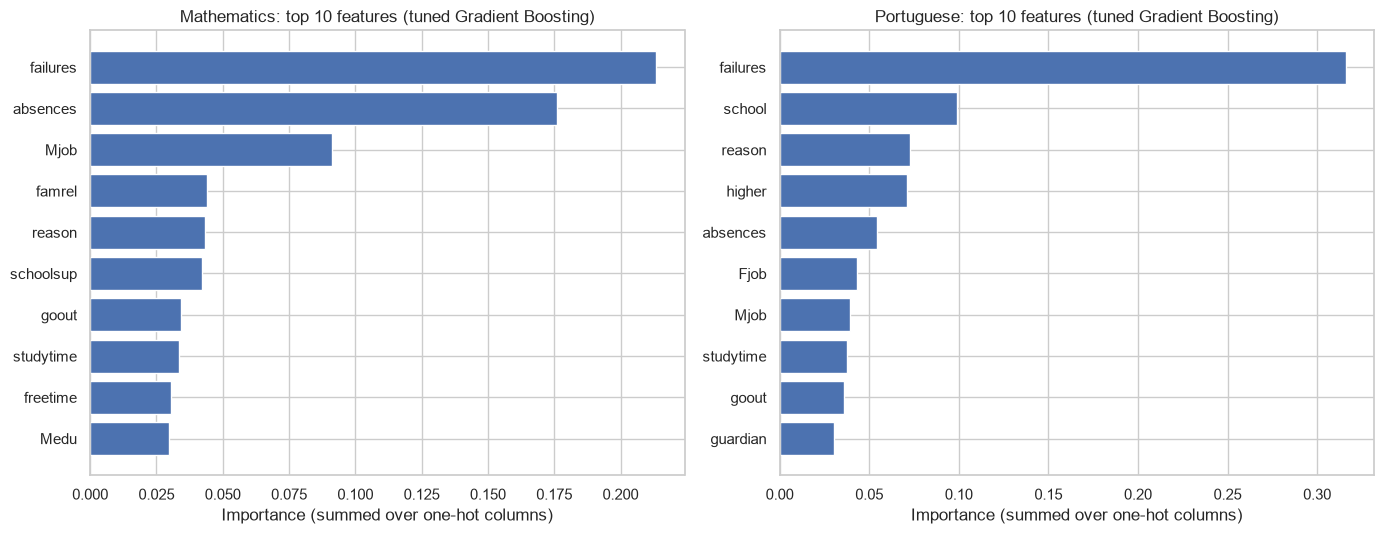

In [ ]:
def importance_tables(model):
    """Importance per transformed column and per original column, from one fitted pipeline."""
    preprocessor = model.named_steps["preprocessor"]
    names = preprocessor.get_feature_names_out()
    values = model.named_steps["classifier"].feature_importances_
    transformed = pd.DataFrame({"Feature": names, "Importance": values}).sort_values("Importance", ascending=False)

    categorical = [c for name, _, cols in preprocessor.transformers_ if name == "cat" for c in cols]

    def original_name(feature):
        body = feature.split("__", 1)[1]
        if feature.startswith("cat__"):
            for col in sorted(categorical, key=len, reverse=True):
                if body.startswith(col + "_"):
                    return col
        return body

    original = (transformed.assign(Feature=transformed["Feature"].map(original_name))
                .groupby("Feature", as_index=False)["Importance"].sum()
                .sort_values("Importance", ascending=False))
    return transformed, original

importance_transformed, importance_original = {}, {}
for s in SUBJECTS:
    importance_transformed[s], importance_original[s] = importance_tables(tuned_models[s])
    print(f"\n{s}: top 5 transformed features")
    display(importance_transformed[s].head(5).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, s in zip(axes, SUBJECTS):
    top = importance_original[s].head(10).sort_values("Importance")
    ax.barh(top["Feature"], top["Importance"])
    ax.set_title(f"{s}: top 10 features (tuned Gradient Boosting)")
    ax.set_xlabel("Importance (summed over one-hot columns)")
plt.tight_layout()
plt.show()

In [ ]:
top5 = {s: importance_original[s].head(5)["Feature"].tolist() for s in SUBJECTS}
for s in SUBJECTS:
    print(f"{s}: top 5 original features: {', '.join(top5[s])}")
shared = [f for f in top5["Mathematics"] if f in top5["Portuguese"]]
print("Shared by both subjects' top 5:", ", ".join(shared) if shared else "none")
print("Reminder: importance shows model reliance, not cause and effect.")

Mathematics: top 5 original features: failures, absences, Mjob, famrel, reason
Portuguese: top 5 original features: failures, school, reason, higher, absences
Shared by both subjects' top 5: failures, absences, reason
Reminder: importance shows model reliance, not cause and effect.


## Step 10: Final results and recommendation

- **What are we doing?** Collecting the baseline metrics, tuned metrics, best hyperparameters, comparison and top features into one report.
- **Why?** This is the section to read, present and copy into the group report. Every number below comes from the cells above.
- **What does the code produce?** A summary per dataset and a computed recommendation, then the saved models and CSV reports.
- **How to interpret it?** Read each dataset block separately, because the two subjects are modelled independently and have different class balance.

In [ ]:
for s in SUBJECTS:
    best = tuning_df.set_index("Dataset").loc[s]
    print("=" * 72)
    print(f"{s.upper()}  |  Gradient Boosting  |  held-out test set ({len(data[s]['y_test'])} students)")
    print("=" * 72)
    display(comparison_tables[s].round(4))
    print("Best hyperparameters:", best["Best parameters"])
    print(f"Mean CV F1 (training folds): tuned {best['Best CV F1']:.4f}, "
          f"default settings {best['Baseline CV F1 (default settings)']:.4f}")
    print("Top features (tuned model):", ", ".join(importance_original[s].head(5)["Feature"]))
    print()

MATHEMATICS  |  Gradient Boosting  |  held-out test set (79 students)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.6582,0.6709,0.0127
Precision,0.4667,0.5000,0.0333
Recall,0.2692,0.2692,0.0000
F1-Score,0.3415,0.3500,0.0085
ROC-AUC,0.6727,0.6372,-0.0356


Best hyperparameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 100}
Mean CV F1 (training folds): tuned 0.4472, default settings 0.4521
Top features (tuned model): failures, absences, Mjob, famrel, reason

PORTUGUESE  |  Gradient Boosting  |  held-out test set (130 students)


,Baseline,Tuned,Change (Tuned - Baseline)
Accuracy,0.8385,0.8308,-0.0077
Precision,0.4444,0.4000,-0.0444
Recall,0.2000,0.2000,0.0000
F1-Score,0.2759,0.2667,-0.0092
ROC-AUC,0.7905,0.7800,-0.0105


Best hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 50}
Mean CV F1 (training folds): tuned 0.4201, default settings 0.3757
Top features (tuned model): failures, school, reason, higher, absences



In [ ]:
print("COMPUTED INTERPRETATION (generated from this run's results)\n")
for s in SUBJECTS:
    b, t = baseline_eval[s]["metrics"], tuned_eval[s]["metrics"]

    better_f1 = "tuned" if t["F1-Score"] > b["F1-Score"] else "baseline" if b["F1-Score"] > t["F1-Score"] else "neither (tie)"
    better_recall = "tuned" if t["Recall"] > b["Recall"] else "baseline" if b["Recall"] > t["Recall"] else "neither (tie)"
    best_recall = max(b["Recall"], t["Recall"])

    print(f"{s}:")
    print(f"  Higher test F1: {better_f1} (baseline {b['F1-Score']:.3f}, tuned {t['F1-Score']:.3f}).")
    print(f"  Higher test recall: {better_recall} (baseline {b['Recall']:.3f}, tuned {t['Recall']:.3f}).")
    print(f"  ROC-AUC: baseline {b['ROC-AUC']:.3f}, tuned {t['ROC-AUC']:.3f}.")
    if best_recall < 0.5:
        print(f"  Warning: even the better model detects only {best_recall:.0%} of at-risk students at the default "
              "0.5 threshold, so it should not be the only screening tool.")
    else:
        print(f"  The better model detects {best_recall:.0%} of at-risk students at the default 0.5 threshold.")
    print()

COMPUTED INTERPRETATION (generated from this run's results)

Mathematics:
  Higher test F1: tuned (baseline 0.341, tuned 0.350).
  Higher test recall: neither (tie) (baseline 0.269, tuned 0.269).
  ROC-AUC: baseline 0.673, tuned 0.637.

Portuguese:
  Higher test F1: baseline (baseline 0.276, tuned 0.267).
  Higher test recall: neither (tie) (baseline 0.200, tuned 0.200).
  ROC-AUC: baseline 0.790, tuned 0.780.



### Strengths, limitations and responsible use

**Strengths**
- Gradient Boosting can capture non-linear patterns and interactions between inputs.
- The pipeline fits preprocessing on training data only, the split is stratified and reproducible, and tuning never sees the test set.
- Evaluation reports recall, precision, F1 and ROC-AUC for the At-Risk class, not only accuracy.

**Limitations**
- The datasets are small, so the test set holds few at-risk students and the metrics are noisy. One train-test split does not show how much results vary.
- The default 0.5 decision threshold may not suit early identification. A lower threshold would raise recall at the cost of more false alarms. This notebook keeps the original methodology and does not tune the threshold.
- The data come from two Portuguese secondary schools. Performance may not carry over to other schools or later cohorts.
- Gradient Boosting is harder to explain than a single tree, and feature importance is not causal.
- Several inputs describe family background and personal circumstances. Predictions based on them can reflect existing inequalities.

**Responsible use**
- Treat a prediction as a prompt for a conversation with the student and educators, not as a label or a decision.
- Validate the model on local data before any real use, and review errors for groups that may be treated unfairly.
- The notebook's computed interpretation above is the evidence to cite in the assignment report. Check it against the tables before copying it.

### Save models and reports

Writes the fitted models and metric tables to `notebooks/models` and `notebooks/reports` (set `SAVE_OUTPUTS = False` in Step 1 to skip). The file names match the original notebook.

In [ ]:
if SAVE_OUTPUTS:
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    REPORT_DIR.mkdir(parents=True, exist_ok=True)

    for s in SUBJECTS:
        joblib.dump(baseline_models[s], MODEL_DIR / f"gradient_boosting_{s.lower()}.joblib")
        joblib.dump(tuned_models[s], MODEL_DIR / f"gradient_boosting_{s.lower()}_tuned.joblib")
        importance_transformed[s].to_csv(REPORT_DIR / f"gradient_boosting_{s.lower()}_feature_importance.csv", index=False)

    baseline_df.to_csv(REPORT_DIR / "gradient_boosting_baseline_metrics.csv", index=False)
    tuned_out = tuned_df.merge(
        tuning_df[["Dataset", "Best parameters", "Best CV F1"]].rename(columns={"Best CV F1": "CV F1-Score"}),
        on="Dataset")
    tuned_out.to_csv(REPORT_DIR / "gradient_boosting_tuned_metrics.csv", index=False)
    comparison_long.to_csv(REPORT_DIR / "gradient_boosting_baseline_vs_tuned.csv", index=False)

    print("Saved models and reports to:")
    print(" ", MODEL_DIR.resolve())
    print(" ", REPORT_DIR.resolve())
else:
    print("SAVE_OUTPUTS is False: nothing was written.")

Saved models and reports to:
  C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\notebooks\models
  C:\Users\USER\Downloads\student-at-risk-full-project (1)\student-at-risk-full-project\notebooks\reports
